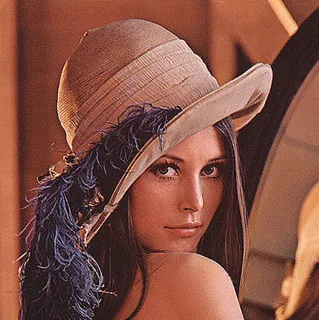

In [3]:
from PIL import Image
import struct
import ctypes

img = Image.open('lena.png')
(w, h) = img.size[0:2]
pix = img.load()
buff = ctypes.create_string_buffer(4 * w * h)
offset = 0
for j in range(h):
	for i in range(w):
		r = bytes((pix[i, j][0],))
		g = bytes((pix[i, j][1],))
		b = bytes((pix[i, j][2],))
		a = bytes((255,))
		struct.pack_into('cccc', buff, offset, r, g, b, a)
		offset += 4
out = open('in.data', 'wb')
out.write(struct.pack('ii', w, h))
out.write(buff.raw)
out.close()

display(img)

In [ ]:
from PIL import Image
import struct
import ctypes

TARGET = 5000

img = Image.open('lena.png').convert('RGBA')
img = img.resize((TARGET, TARGET), Image.LANCZOS)

w, h = img.size
pix = img.load()

buff = ctypes.create_string_buffer(4 * w * h)
offset = 0
for j in range(h):
    for i in range(w):
        r, g, b, a = pix[i, j]
        struct.pack_into('cccc', buff, offset,
                         bytes((r,)), bytes((g,)), bytes((b,)), bytes((a,)))
        offset += 4

with open('in_5000.data', 'wb') as out:
    out.write(struct.pack('ii', w, h))
    out.write(buff.raw)

In [3]:
%%writefile lab2.cu

#include <iostream>
#include <cmath>
#include <iomanip>
#include <vector>
#include <string>
#include <cstring>
#include <fstream>
#include <cstdlib>

#define CSC(call) \
do { \
    cudaError_t res = call; \
    if (res != cudaSuccess) { \
        fprintf(stderr, "ERROR in %s:%d. Message: %s\n", \
            __FILE__, __LINE__, cudaGetErrorString(res)); \
        exit(0); \
    } \
} while(0)


__device__ float get_y(cudaTextureObject_t tex, float x, float y) {
    uchar4 p = tex2D<uchar4>(tex, x + 0.5, y + 0.5);
    return 0.299 * p.x + 0.587 * p.y + 0.114 * p.z;
}

__global__ void kernel(cudaTextureObject_t tex, uchar4 *out, int w, int h) {
    int idx = blockDim.x * blockIdx.x + threadIdx.x;
    int idy = blockDim.y * blockIdx.y + threadIdx.y;
    int offsetx = blockDim.x * gridDim.x;
    int offsety = blockDim.y * gridDim.y;
    int x, y;

    for (y = idy; y < h; y += offsety) {
        for (x = idx; x < w; x += offsetx) {
            float g00 = get_y(tex, x - 1, y - 1); // достаточно ли float..
            float g10 = get_y(tex, x, y - 1);
            float g20 = get_y(tex, x + 1, y - 1);

            float g01 = get_y(tex, x - 1, y);
            float g21 = get_y(tex, x + 1, y);

            float g02 = get_y(tex, x - 1, y + 1);
            float g12 = get_y(tex, x, y + 1);
            float g22 = get_y(tex, x + 1, y + 1);

            float gx = -g00 + g20 - 2.0 * g01 + 2.0 * g21 - g02 + g22;
            float gy = -g00 - 2.0 * g10 - g20 + g02 + 2.0 * g12 + g22;

            float g = sqrtf(gx * gx + gy * gy);
            if (g > 255.0) {
                g = 255.0;
            }

            uchar4 p = tex2D<uchar4>(tex, x + 0.5, y + 0.5);
            out[y * w + x] = make_uchar4((unsigned char)g, (unsigned char)g, (unsigned char)g, p.w);
        }
    }
}


int main(int argc, char* argv[]) {
    int blocksPerGrid = 1024; // База
    int threadsPerBlock = 1024;
    std::string filename = "";

    for (int i = 1; i < argc; ++i) {
        if (std::strcmp(argv[i], "-f") == 0 && i + 1 < argc) {
            filename = argv[++i];
        } else if (std::strcmp(argv[i], "-grid") == 0 && i + 1 < argc) {
            blocksPerGrid = std::atoi(argv[++i]);
        } else if (std::strcmp(argv[i], "-block") == 0 && i + 1 < argc) {
            threadsPerBlock = std::atoi(argv[++i]);
        }
    }




    char in_path[256], out_path[256];
    scanf("%s %s", in_path, out_path);

    int w, h;
    FILE *fp = fopen(in_path, "rb");
    fread(&w, sizeof(int), 1, fp);
    fread(&h, sizeof(int), 1, fp);
    uchar4 *data = (uchar4 *)malloc(sizeof(uchar4) * w * h);
    fread(data, sizeof(uchar4), w * h, fp);
    fclose(fp);

    cudaArray *arr;
    cudaChannelFormatDesc ch = cudaCreateChannelDesc<uchar4>();
    CSC(cudaMallocArray(&arr, &ch, w, h));
    CSC(cudaMemcpy2DToArray(arr, 0, 0, data, w * sizeof(uchar4), w * sizeof(uchar4), h, cudaMemcpyHostToDevice));

    struct cudaResourceDesc resDesc;
    memset(&resDesc, 0, sizeof(resDesc));
    resDesc.resType = cudaResourceTypeArray;
    resDesc.res.array.array = arr;

    struct cudaTextureDesc texDesc;
    memset(&texDesc, 0, sizeof(texDesc));
    texDesc.addressMode[0] = cudaAddressModeClamp;
    texDesc.addressMode[1] = cudaAddressModeClamp;
    texDesc.filterMode = cudaFilterModePoint;
    texDesc.readMode = cudaReadModeElementType;
    texDesc.normalizedCoords = false;

    cudaTextureObject_t tex = 0;
    CSC(cudaCreateTextureObject(&tex, &resDesc, &texDesc, NULL));

    uchar4 *dev_out;
    CSC(cudaMalloc(&dev_out, sizeof(uchar4) * w * h));

    cudaEvent_t start, stop;
    CSC(cudaEventCreate(&start));
    CSC(cudaEventCreate(&stop));

    CSC(cudaEventRecord(start));

    kernel<<< blocksPerGrid, threadsPerBlock >>>(tex, dev_out, w, h);

    CSC(cudaEventRecord(stop));
    CSC(cudaEventSynchronize(stop));
    CSC(cudaGetLastError());

    float time_ms = 0.0f;
    CSC(cudaEventElapsedTime(&time_ms, start, stop));

    CSC(cudaEventDestroy(start));
    CSC(cudaEventDestroy(stop));

    fprintf(stderr, "TIME_MS: %f\n", time_ms);

    CSC(cudaMemcpy(data, dev_out, sizeof(uchar4) * w * h, cudaMemcpyDeviceToHost));

    CSC(cudaDestroyTextureObject(tex));
    CSC(cudaFreeArray(arr));
    CSC(cudaFree(dev_out));

    fp = fopen(out_path, "wb");
    fwrite(&w, sizeof(int), 1, fp);
    fwrite(&h, sizeof(int), 1, fp);
    fwrite(data, sizeof(uchar4), w * h, fp);
    fclose(fp);

    free(data);
    return 0;
}

Overwriting lab2.cu


In [15]:
%%writefile lab2cpu.cpp

#include <iostream>
#include <cmath>
#include <iomanip>
#include <vector>
#include <string>
#include <cstring>
#include <fstream>
#include <cstdlib>
#include <chrono>


struct uchar4 {
    uint8_t x, y, z, w; // для хранения пикселей 
};

inline int clamp(int val, int max_val) {
    if (val < 0) return 0;
    if (val >= max_val) return max_val - 1;
    return val;
}


inline float get_y(const uchar4* data, int w, int h, int x, int y) {
    int cx = clamp(x, w);
    int cy = clamp(y, h);
    uchar4 p = data[cy * w + cx];
    return 0.299 * p.x + 0.587 * p.y + 0.114 * p.z;
}

int main(int argc, char* argv[]) {
    int blocksPerGrid = 1024;
    int threadsPerBlock = 1024;
    std::string filename = "";

    for (int i = 1; i < argc; ++i) {
        if (std::strcmp(argv[i], "-f") == 0 && i + 1 < argc) {
            filename = argv[++i];
        } else if (std::strcmp(argv[i], "-grid") == 0 && i + 1 < argc) {
            blocksPerGrid = std::atoi(argv[++i]);
        } else if (std::strcmp(argv[i], "-block") == 0 && i + 1 < argc) {
            threadsPerBlock = std::atoi(argv[++i]);
        }
    }

    char in_path[256], out_path[256];
    scanf("%s %s", in_path, out_path);

    int w, h;
    FILE *fp = fopen(in_path, "rb");
    fread(&w, sizeof(int), 1, fp);
    fread(&h, sizeof(int), 1, fp);
    uchar4 *data = (uchar4 *)malloc(sizeof(uchar4) * w * h);
    fread(data, sizeof(uchar4), w * h, fp);
    fclose(fp);

    uchar4 *out = (uchar4 *)malloc(sizeof(uchar4) * w * h);

    auto start = std::chrono::high_resolution_clock::now();

    for (int y = 0; y < h; ++y) {
        for (int x = 0; x < w; ++x) {
            float g00 = get_y(data, w, h, x - 1, y - 1);  // достаточно ли float..
            float g10 = get_y(data, w, h, x, y - 1);
            float g20 = get_y(data, w, h, x + 1, y - 1);

            float g01 = get_y(data, w, h, x - 1, y);
            float g21 = get_y(data, w, h, x + 1, y);

            float g02 = get_y(data, w, h, x - 1, y + 1);
            float g12 = get_y(data, w, h, x, y + 1);
            float g22 = get_y(data, w, h, x + 1, y + 1);

            float gx = -g00 + g20 - 2.0 * g01 + 2.0 * g21 - g02 + g22;
            float gy = -g00 - 2.0 * g10 - g20 + g02 + 2.0 * g12 + g22;

            float g = sqrtf(gx * gx + gy * gy);
            if (g > 255.0) {
                g = 255.0;
            }

            uchar4 p = data[y * w + x];
            out[y * w + x] = uchar4{(uint8_t)g, (uint8_t)g, (uint8_t)g, (uint8_t)p.w};
        }
    }

    auto end = std::chrono::high_resolution_clock::now();

    std::chrono::duration elapsed = end - start;
    double time_ms = elapsed.count();

    std::cerr << "TIME_MS: " << time_ms << "\n";

    fp = fopen(out_path, "wb");
    fwrite(&w, sizeof(int), 1, fp);
    fwrite(&h, sizeof(int), 1, fp);
    fwrite(out, sizeof(uchar4), w * h, fp);
    fclose(fp);

    free(data);
    free(out);
    return 0;
}

Overwriting lab2cpu.cpp


In [4]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2023 NVIDIA Corporation
Built on Fri_Nov__3_17:51:05_Pacific_Daylight_Time_2023
Cuda compilation tools, release 12.3, V12.3.103
Build cuda_12.3.r12.3/compiler.33492891_0


In [17]:
import subprocess
import re
import os
import random
import pandas as pd
import struct
from PIL import Image
from IPython.display import display
import cv2
import matplotlib.pyplot as plt

In [ ]:
print("\nКомпиляция lab2.cu...")
compile_res = subprocess.run(
    [
        "nvcc",
        "-allow-unsupported-compiler",
        "-Xcompiler",
        "-D_ALLOW_COMPILER_AND_STL_VERSION_MISMATCH", # иначе не работает....
        "-O3",
        "lab2.cu",
        "-o",
        "lab2.exe",
    ],
    capture_output=True,
)

stdout_msg = compile_res.stdout.decode("cp1251", errors="replace")
stderr_msg = compile_res.stderr.decode("cp1251", errors="replace")

if compile_res.returncode != 0:
    print("Ошибка компиляции:")
    if stdout_msg:
        print("STDOUT:\n", stdout_msg)
    if stderr_msg:
        print("STDERR:\n", stderr_msg)
else:
    print("Компиляция успешно завершена (lab2.exe создан).")


Компиляция lab2.cu...
Компиляция успешно завершена (lab2.exe создан).


In [ ]:
import subprocess

vcvars_path = r"C:\Program Files (x86)\Microsoft Visual Studio\2022\BuildTools\VC\Auxiliary\Build\vcvars64.bat"

cmd = f'"{vcvars_path}" && cl lab2cpu.cpp /EHsc /std:c++17 /Fe:lab2cpu.exe'

compile_res = subprocess.run(
    cmd,
    shell=True,
    capture_output=True,
)

stdout_msg = compile_res.stdout.decode("cp1251", errors="replace")
stderr_msg = compile_res.stderr.decode("cp1251", errors="replace")

if compile_res.returncode != 0:
    print("Ошибка компиляции:")
    if stdout_msg:
        print("STDOUT:\n", stdout_msg)
    if stderr_msg:
        print("STDERR:\n", stderr_msg)
else:
    print("Компиляция успешно завершена (lab2cpu.exe создан).")

Компиляция успешно завершена (lab2cpu.exe создан).


In [7]:
res = subprocess.run(
    [r".\lab2.exe"],
    input="in.data out.data",
    text=True,
    capture_output=True,
    encoding="cp1251",
    errors="replace",
)

print(res.stdout)

In [8]:
with open("in2.data", "rb") as f:
    w, h = struct.unpack("ii", f.read(8))
    raw_data = f.read()

print(len(raw_data))
print(raw_data[:36]) 

36
b'\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x80\x80\x80\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00'


In [9]:
with open("out1.data", "rb") as f:
    w, h = struct.unpack("ii", f.read(8))
    raw_data = f.read()

print(len(raw_data))
print(raw_data[:36]) 

36
b'\x14\x14\x14\x00\x0c\x0c\x0c\x00\x11\x11\x11\x00\x13\x13\x13\x00\x15\x15\x15\x00\x18\x18\x18\x00999\x00\x14\x14\x14\x00???\x00'


In [10]:
with open("out_t1.data", "rb") as f:
    w, h = struct.unpack("ii", f.read(8))
    raw_data = f.read()

print(len(raw_data))
print(raw_data[:36]) 

36
b'\x14\x14\x14\x00\x0c\x0c\x0c\x00\x11\x11\x11\x00\x13\x13\x13\x00\x15\x15\x15\x00\x18\x18\x18\x00999\x00\x14\x14\x14\x00???\x00'


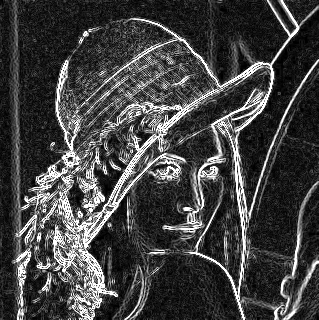

In [11]:
with open("out.data", "rb") as f:
    w, h = struct.unpack("ii", f.read(8))
    raw_data = f.read()

img = Image.frombytes("RGBA", (w, h), raw_data)
display(img)

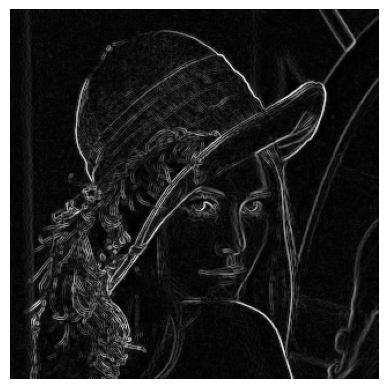

In [12]:
img = cv2.imread("lena.png", cv2.IMREAD_GRAYSCALE)

gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

edges = cv2.magnitude(gx, gy)

plt.imshow(edges, cmap="gray")
plt.axis("off")
plt.show()

In [18]:
from tqdm import tqdm

In [21]:
configs = [
    #(1, 1),
    (1, 32),
    (1, 64),
    (1, 128),
    (1, 256),
    (1, 512),
    (16, 16),
    (16, 32),
    (16, 64),
    (16, 128),
    (16, 256),
    (16, 512),
    (32, 32),
    (32, 64),
    (32, 128),
    (32, 256),
    (32, 512),
    (64, 64),
    (64, 128),
    (32, 256),
    (128, 128),
    (128, 256),
    (128, 512),
    (512, 512),
    (1024, 1024),
    #(2048, 2048)
]

results = []

for fname in ["in.data", "in_5000.data"]:
    for grid, block in tqdm(configs):
        cmd = [r".\lab2.exe", "-grid", str(grid), "-block", str(block)]

        t_gpu = 0.0
        for repeat in range(3):
            proc = subprocess.run(
                cmd,
                input=f"{fname} out.data\n",
                stdout=subprocess.DEVNULL,
                stderr=subprocess.PIPE,
                text=True,
                encoding="cp1251",
                errors="replace",
            )

            match = re.search(r"TIME_MS:\s*([\d\.]+)", proc.stderr)
            t_gpu_t = float(match.group(1)) if match else None
            t_gpu += t_gpu_t

        results.append(
            {
                "Файл / Набор": fname,
                "Grid": grid,
                "Block": block,
                "Конфигурация": f"<<< {grid}, {block} >>>",
                "Время GPU (мс)": t_gpu/3.0,
            }
        )

df = pd.DataFrame(results)
df

100%|██████████| 24/24 [00:53<00:00,  2.21s/it]


,Файл / Набор,Grid,Block,Конфигурация,Время GPU (мс)
0,in.data,1,32,"<<< 1, 32 >>>",8.082432
1,in.data,1,64,"<<< 1, 64 >>>",5.630976
2,in.data,1,128,"<<< 1, 128 >>>",5.237419
3,in.data,1,256,"<<< 1, 256 >>>",5.299883
4,in.data,1,512,"<<< 1, 512 >>>",5.186560
5,in.data,16,16,"<<< 16, 16 >>>",1.729536
6,in.data,16,32,"<<< 16, 32 >>>",0.948224
7,in.data,16,64,"<<< 16, 64 >>>",1.253717
8,in.data,16,128,"<<< 16, 128 >>>",2.127531
9,in.data,16,256,"<<< 16, 256 >>>",4.163925


In [20]:

results = []

for fname in ["in.data", "in_5000.data"]:
    cmd = [r".\lab2cpu.exe"]

    t_gpu = 0.0
    for repeat in range(3):
        proc = subprocess.run(
            cmd,
            input=f"{fname} out.data\n",
            stdout=subprocess.DEVNULL,
            stderr=subprocess.PIPE,
            text=True,
            encoding="cp1251",
            errors="replace",
        )

        match = re.search(r"TIME_MS:\s*([\d\.]+)", proc.stderr)
        t_gpu_t = float(match.group(1)) if match else None
        t_gpu += t_gpu_t

    results.append(
        {
            "Файл / Набор": fname,
            "Grid": None,
            "Block": None,
            "Конфигурация": f"cpu",
            "Время GPU (мс)": t_gpu/3.0,
        }
    )

df = pd.DataFrame(results)
df

,Файл / Набор,Grid,Block,Конфигурация,Время GPU (мс)
0,in.data,None,None,cpu,6.941467
1,in_5000.data,None,None,cpu,1.568937


In [1]:
%%writefile info.cu
#include <stdio.h>

int main() {
	int deviceCount;
	cudaDeviceProp devProp;
	cudaGetDeviceCount(&deviceCount);
	printf("Found %d devices\n", deviceCount);
	for(int device = 0;device < deviceCount;device++) {
		cudaGetDeviceProperties(&devProp, device);
		printf("Device %d\n", device);
		printf("Compute capability      : %d.%d\n", devProp.major, devProp.minor);
		printf("Name                    : %s\n", devProp.name);
		printf("Total Global Memory     : %zu\n", devProp.totalGlobalMem);
		printf("Shared memory per block : %zu\n", devProp.sharedMemPerBlock);
		printf("Registers per block     : %d\n", devProp.regsPerBlock);
		printf("Warp size               : %d\n", devProp.warpSize);
		printf("Max threads per block   : (%d, %d, %d)\n", devProp.maxThreadsDim[0], devProp.maxThreadsDim[1], devProp.maxThreadsDim[2]);
		printf("Max block   : (%d, %d, %d)\n", devProp.maxGridSize[0], devProp.maxGridSize[1], devProp.maxGridSize[2]);
		printf("Total constant memory   : %zu\n", devProp.totalConstMem);
		printf("Multiprocessors count   : %d\n", devProp.multiProcessorCount);
	}
	return 0;
}

Writing info.cu


UsageError: Cell magic `%%shell` not found.
